### Predictive maintainence problem of Microsoft Azure Machine

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
#pd.pandas.set_option('display.max_rows',None)

In [2]:
machine=pd.read_csv("PdM_machines.csv")
machine

,machineID,model,age
0,1,model3,18
1,2,model4,7
2,3,model3,8
3,4,model3,7
4,5,model3,2
...,...,...,...
95,96,model2,10
96,97,model2,14
97,98,model2,20
98,99,model1,14


In [3]:
machine.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   machineID  100 non-null    int64 
 1   model      100 non-null    object
 2   age        100 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 2.5+ KB


In [4]:
telemetry=pd.read_csv("PdM_telemetry.csv")
#telemetry

In [5]:
telemetry.isna().sum()
telemetry.describe()

,machineID,volt,rotate,pressure,vibration
count,876100.000000,876100.000000,876100.000000,876100.000000,876100.000000
mean,50.500000,170.777736,446.605119,100.858668,40.385007
std,28.866087,15.509114,52.673886,11.048679,5.370361
min,1.000000,97.333604,138.432075,51.237106,14.877054
25%,25.750000,160.304927,412.305714,93.498181,36.777299
50%,50.500000,170.607338,447.558150,100.425559,40.237247
75%,75.250000,181.004493,482.176600,107.555231,43.784938
max,100.000000,255.124717,695.020984,185.951998,76.791072


In [6]:
telemetry.shape

(876100, 6)

In [7]:
machine['machineID'].nunique()

100

In [8]:
telemetry.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 876100 entries, 0 to 876099
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   datetime   876100 non-null  object 
 1   machineID  876100 non-null  int64  
 2   volt       876100 non-null  float64
 3   rotate     876100 non-null  float64
 4   pressure   876100 non-null  float64
 5   vibration  876100 non-null  float64
dtypes: float64(4), int64(1), object(1)
memory usage: 40.1+ MB


In [9]:
errors=pd.read_csv("PdM_errors.csv")
errors

,datetime,machineID,errorID
0,2015-01-03 07:00:00,1,error1
1,2015-01-03 20:00:00,1,error3
2,2015-01-04 06:00:00,1,error5
3,2015-01-10 15:00:00,1,error4
4,2015-01-22 10:00:00,1,error4
...,...,...,...
3914,2015-11-21 08:00:00,100,error2
3915,2015-12-04 02:00:00,100,error1
3916,2015-12-08 06:00:00,100,error2
3917,2015-12-08 06:00:00,100,error3


In [10]:
errors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3919 entries, 0 to 3918
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   datetime   3919 non-null   object
 1   machineID  3919 non-null   int64 
 2   errorID    3919 non-null   object
dtypes: int64(1), object(2)
memory usage: 92.0+ KB


In [11]:
errors.isnull().sum()
errors.machineID.value_counts()
#print(errors["machineID"].to_string())

machineID
22    60
99    54
78    54
15    51
81    51
      ..
2     28
86    27
31    26
6     23
77    22
Name: count, Length: 100, dtype: int64

In [12]:
maintenance=pd.read_csv("PdM_maint.csv")
maintenance

,datetime,machineID,comp
0,2014-06-01 06:00:00,1,comp2
1,2014-07-16 06:00:00,1,comp4
2,2014-07-31 06:00:00,1,comp3
3,2014-12-13 06:00:00,1,comp1
4,2015-01-05 06:00:00,1,comp4
...,...,...,...
3281,2015-10-10 06:00:00,100,comp3
3282,2015-10-25 06:00:00,100,comp4
3283,2015-11-09 06:00:00,100,comp4
3284,2015-12-09 06:00:00,100,comp2


In [13]:
maintenance.machineID.value_counts()


machineID
66    39
70    39
68    39
24    38
42    38
      ..
47    27
89    27
91    27
74    26
53    25
Name: count, Length: 100, dtype: int64

In [14]:
maintenance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3286 entries, 0 to 3285
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   datetime   3286 non-null   object
 1   machineID  3286 non-null   int64 
 2   comp       3286 non-null   object
dtypes: int64(1), object(2)
memory usage: 77.1+ KB


In [15]:
failures=pd.read_csv("PdM_failures.csv")
failures

,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4
...,...,...,...
756,2015-11-29 06:00:00,99,comp3
757,2015-12-14 06:00:00,99,comp4
758,2015-02-12 06:00:00,100,comp1
759,2015-09-10 06:00:00,100,comp1


In [16]:
failures.failure.value_counts()

failure
comp2    259
comp1    192
comp4    179
comp3    131
Name: count, dtype: int64

In [17]:
# To convert the object of column "dateetime" in Telemetry to datetime datatype
telemetry['datetime'] = pd.to_datetime(
    telemetry['datetime']
)

In [18]:
telemetry['datetime']

0        2015-01-01 06:00:00
1        2015-01-01 07:00:00
2        2015-01-01 08:00:00
3        2015-01-01 09:00:00
4        2015-01-01 10:00:00
                 ...        
876095   2016-01-01 02:00:00
876096   2016-01-01 03:00:00
876097   2016-01-01 04:00:00
876098   2016-01-01 05:00:00
876099   2016-01-01 06:00:00
Name: datetime, Length: 876100, dtype: datetime64[ns]

In [19]:
# To convert the object of column "dateetime" in errors to datetime datatype
errors['datetime']=pd.to_datetime(errors['datetime'])
errors['datetime']

0      2015-01-03 07:00:00
1      2015-01-03 20:00:00
2      2015-01-04 06:00:00
3      2015-01-10 15:00:00
4      2015-01-22 10:00:00
               ...        
3914   2015-11-21 08:00:00
3915   2015-12-04 02:00:00
3916   2015-12-08 06:00:00
3917   2015-12-08 06:00:00
3918   2015-12-22 03:00:00
Name: datetime, Length: 3919, dtype: datetime64[ns]

In [20]:
# To convert the object of column "dateetime" in Failure dataset to datetime datatype itself

failures['datetime']=pd.to_datetime(failures['datetime'])
failures['datetime']

0     2015-01-05 06:00:00
1     2015-03-06 06:00:00
2     2015-04-20 06:00:00
3     2015-06-19 06:00:00
4     2015-09-02 06:00:00
              ...        
756   2015-11-29 06:00:00
757   2015-12-14 06:00:00
758   2015-02-12 06:00:00
759   2015-09-10 06:00:00
760   2015-12-09 06:00:00
Name: datetime, Length: 761, dtype: datetime64[ns]

In [21]:
# To convert the object of column "dateetime" in Maintainence to datetime datatype itself
maintenance['datetime']=pd.to_datetime(maintenance['datetime'])
maintenance['datetime']

0      2014-06-01 06:00:00
1      2014-07-16 06:00:00
2      2014-07-31 06:00:00
3      2014-12-13 06:00:00
4      2015-01-05 06:00:00
               ...        
3281   2015-10-10 06:00:00
3282   2015-10-25 06:00:00
3283   2015-11-09 06:00:00
3284   2015-12-09 06:00:00
3285   2015-12-24 06:00:00
Name: datetime, Length: 3286, dtype: datetime64[ns]

In [22]:
telemetry.describe()

,datetime,machineID,volt,rotate,pressure,vibration
count,876100,876100.000000,876100.000000,876100.000000,876100.000000,876100.000000
mean,2015-07-02 18:00:00,50.500000,170.777736,446.605119,100.858668,40.385007
min,2015-01-01 06:00:00,1.000000,97.333604,138.432075,51.237106,14.877054
25%,2015-04-02 12:00:00,25.750000,160.304927,412.305714,93.498181,36.777299
50%,2015-07-02 18:00:00,50.500000,170.607338,447.558150,100.425559,40.237247
75%,2015-10-02 00:00:00,75.250000,181.004493,482.176600,107.555231,43.784938
max,2016-01-01 06:00:00,100.000000,255.124717,695.020984,185.951998,76.791072
std,NaN,28.866087,15.509114,52.673886,11.048679,5.370361


### Finding the skewness& outliers

In [23]:
telemetry[['volt',
'rotate',
'pressure',
'vibration']].skew()

volt         0.086717
rotate      -0.142298
pressure     0.403409
vibration    0.248708
dtype: float64

### Merging telemetry data with machine data containing model and age in a single dataset.

In [24]:
data_telemetry=telemetry.merge(machine,on='machineID',how='left')

In [25]:
errors['errorID'].value_counts()

errorID
error1    1010
error2     988
error3     838
error4     727
error5     356
Name: count, dtype: int64

### Checking whether every error has occured atleast once in all 100 machines

In [26]:
errors.groupby('errorID')['machineID'].nunique()

errorID
error1    100
error2    100
error3    100
error4    100
error5     93
Name: machineID, dtype: int64

### All errors except error5 has occured in all 100 machines ( 7 machines dont have error5 in other words)

In [27]:
errors.groupby('machineID').size()

machineID
1      35
2      28
3      39
4      31
5      38
       ..
96     39
97     45
98     45
99     54
100    31
Length: 100, dtype: int64

In [28]:
failures['failure'].value_counts().sum

<bound method Series.sum of failure
comp2    259
comp1    192
comp4    179
comp3    131
Name: count, dtype: int64>

In [29]:
failures.groupby('machineID').size()

machineID
1       7
2       4
3       5
4       6
5       7
       ..
96      5
97      8
98     16
99     19
100     3
Length: 98, dtype: int64

### Comp2 has failed morenumber of times (259) and Machine ID 99 has the maximum number of componennt failures(failure=19( followed by machinr ID 98 with 16 failures

###Query : Are there are any errors before the failure of Machine 99. How many errors/frequency of errors occured before the failure of Machine 99? 
##How was the volt/press/vibration before this machine faild?
##Was there any maintainence done brfore failure? If yes how often/duration of maintainence? 


In [30]:
# Checking the data of Machine ID 99 alone and focusing on its failures

mach_99= failures.loc[failures["machineID"] == 99, "failure"]
mach_99.value_counts()

failure
comp3    6
comp2    6
comp4    5
comp1    2
Name: count, dtype: int64

In [228]:
# Get the failure datetimes of Machine ID 99 
mach_99_fail_datetime=failures.loc[failures["machineID"] == 99, "datetime"]
mach_99_fail_datetime=mach_99_fail_datetime.to_list()

In [229]:
# To get all the list of errors occcured 24h before the failure of Machine 99
summary = []

for failure_time in mach_99_fail_datetime:

    errors_24h = errors[
        (errors["machineID"] == 99) &
        (errors["datetime"] >= failure_time - pd.Timedelta(hours=24)) &
        (errors["datetime"] < failure_time)
    ]

    for _, row in errors_24h.iterrows():

        summary.append({
            "failure_time": failure_time,
            "error_time": row["datetime"],
            "errorID_99": row["errorID"],
            "hrs_before_failure":
                (failure_time - row["datetime"]).total_seconds()/3600
        })

error_24h_99 = pd.DataFrame(summary)

In [231]:
#error_24h_99['error_count_24h_99'].value_counts()
error_24h_99

,failure_time,error_time,errorID_99,hrs_before_failure
0,2015-01-18 06:00:00,2015-01-17 06:00:00,error5,24.0
1,2015-02-02 06:00:00,2015-02-01 06:00:00,error1,24.0
2,2015-02-17 06:00:00,2015-02-16 06:00:00,error2,24.0
3,2015-02-17 06:00:00,2015-02-16 06:00:00,error3,24.0
4,2015-03-04 06:00:00,2015-03-03 06:00:00,error4,24.0
5,2015-03-19 06:00:00,2015-03-18 06:00:00,error5,24.0
6,2015-04-03 06:00:00,2015-04-02 06:00:00,error2,24.0
7,2015-04-03 06:00:00,2015-04-02 06:00:00,error3,24.0
8,2015-04-18 06:00:00,2015-04-17 06:00:00,error4,24.0
9,2015-04-18 06:00:00,2015-04-17 16:00:00,error3,14.0



### Max Errors that occured 24 hours before failure of Machine 99 are Error 3 and Error 2. Error3 is with 8 failures & Error2 is wih 7 failures

### Every error of Machine 99 occcured 24 hours earlier except for error3 and errro2 which occured 4 hours, 14 hours and 16 hours respectively. Avergae mean hours of failure of error3 and erro2 are 20.25h and 22.85h 

In [39]:
error_24h_99.groupby("errorID_99").agg({
    "hrs_before_failure":["count","mean"]
})

hrs_before_failure           
                        count       mean
errorID_99                              
error1                      2  24.000000
error2                      7  22.857143
error3                      8  20.250000
error4                      5  24.000000
error5                      5  24.000000

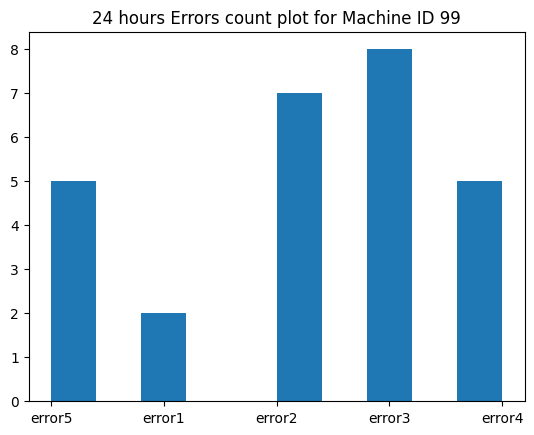

In [232]:

plt.hist(error_24h_99['errorID_99'],label=None)
plt.title('24 hours Errors count plot for Machine ID 99')
plt.show()

In [233]:
# To get all the list of errors occcured 7days before the failure of Machine 99

summary = []

for failure_time in mach_99_fail_datetime:

    errors_24h = errors[
        (errors["machineID"] == 99) &
        (errors["datetime"] >= failure_time - pd.Timedelta(days=7)) &
        (errors["datetime"] < failure_time)
    ]

    for _, row in errors_24h.iterrows():

        summary.append({
            "failure_time": failure_time,
            "error_time": row["datetime"],
            "errorID_7d": row["errorID"],
            "days_before_failure":
                (failure_time - row["datetime"]).total_seconds()/(3600*24),
            "hrs_before_failure":
                (failure_time - row["datetime"]).total_seconds()/(3600)
        })

error_7d_99 = pd.DataFrame(summary)
error_7d_99

,failure_time,error_time,errorID_7d,days_before_failure,hrs_before_failure
0,2015-01-18 06:00:00,2015-01-17 06:00:00,error5,1.000000,24.0
1,2015-02-02 06:00:00,2015-01-28 01:00:00,error2,5.208333,125.0
2,2015-02-02 06:00:00,2015-01-30 10:00:00,error2,2.833333,68.0
3,2015-02-02 06:00:00,2015-02-01 06:00:00,error1,1.000000,24.0
4,2015-02-17 06:00:00,2015-02-16 06:00:00,error2,1.000000,24.0
5,2015-02-17 06:00:00,2015-02-16 06:00:00,error3,1.000000,24.0
6,2015-03-04 06:00:00,2015-02-25 22:00:00,error1,6.333333,152.0
7,2015-03-04 06:00:00,2015-03-03 06:00:00,error4,1.000000,24.0
8,2015-03-19 06:00:00,2015-03-18 06:00:00,error5,1.000000,24.0
9,2015-04-03 06:00:00,2015-04-02 06:00:00,error2,1.000000,24.0


In [234]:
error_7d_99.groupby("errorID_7d")["hrs_before_failure"].mean()

errorID_7d
error1    53.800000
error2    39.222222
error3    43.583333
error4    52.142857
error5    24.000000
Name: hrs_before_failure, dtype: float64

In [235]:
error_7d_99['errorID_7d'].value_counts()

errorID_7d
error3    12
error2     9
error4     7
error5     5
error1     5
Name: count, dtype: int64

In [236]:
error_7d_99.groupby("errorID_7d").agg({
    "hrs_before_failure":["count","mean"]
})

hrs_before_failure           
                        count       mean
errorID_7d                              
error1                      5  53.800000
error2                      9  39.222222
error3                     12  43.583333
error4                      7  52.142857
error5                      5  24.000000

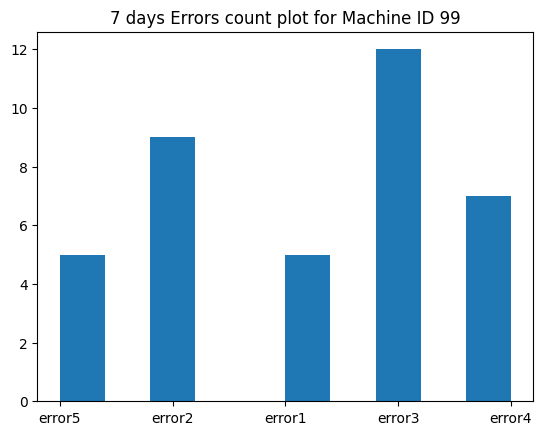

In [45]:
plt.hist(error_7d_99['errorID_7d'],label=None)
plt.title('7 days Errors count plot for Machine ID 99')
plt.show()

### From 7 days data we see that , error3 and error 2 counts lead with 12 and 9 failures respectively.
###Also we see that Avergae mean hours of failure of error3 and erro2 are 43.58h and 39.22h . However in this 7 day window, error5 leads with 24h failure..

In [237]:
summary = []

for failure_time in mach_99_fail_datetime:

    errors_24h = errors[
        (errors["machineID"] == 99) &
        (errors["datetime"] >= failure_time - pd.Timedelta(hours=10)) &
        (errors["datetime"] < failure_time)
    ]

    for _, row in errors_24h.iterrows():

        summary.append({
            "failure_time": failure_time,
            "error_time": row["datetime"],
            "errorID_10h": row["errorID"],
            "hrs_before_failure":
                (failure_time - row["datetime"]).total_seconds()/3600
        })

error_10h_99 = pd.DataFrame(summary)


In [238]:
error_10h_99

,failure_time,error_time,errorID_10h,hrs_before_failure
0,2015-04-18 06:00:00,2015-04-18 02:00:00,error3,4.0


In [239]:
error_10h_99.groupby("errorID_10h").agg({
    "hrs_before_failure":["count","mean"]
})

hrs_before_failure     
                         count mean
errorID_10h                        
error3                       1  4.0

### Inside 10 hrs of failure we see that , error3 alone seem to have occurred with just 1 failure .


### Conclusion of errors heppening with Machine ID 99

✅ Error2 and Error3 appear repeatedly before failures.

✅ Typical lead time seems to be 1-2 days.

✅ Very few error events occur in the last few hours before failure.

✅ Different window sizes (10h, 24h, 7d) produce different patterns, suggesting temporal behavior is important.

In [50]:
errors[errors['machineID']==99].errorID.value_counts()

errorID
error2    17
error3    15
error1     9
error4     8
error5     5
Name: count, dtype: int64

### Non- failure counts of error 3 is 15 for machine 99, whereas before failure accoured we had 8 failures of error3:[This is with respect to error data 24 hrs before failure]


### Error1 : 2/9  = 22%, Error4 : 5/8  = 62.5%, Error5 : 5/5  = 100%, Error3 : 8 / 15 = 53.3%, Error2 : 7 / 17 = 41.2%

In [241]:
# Extending our study to all Machines in regards to errors occurred 24h before every failure
summary = []

for _, failure_row in failures.iterrows():

    failure_time = failure_row["datetime"]
    machine_id = failure_row["machineID"]
    failure_type = failure_row["failure"]

    errors_24h = errors[
        (errors["machineID"] == machine_id) &
        (errors["datetime"] >= failure_time - pd.Timedelta(hours=24)) &
        (errors["datetime"] < failure_time)
    ]

    for _, error_row in errors_24h.iterrows():

        summary.append({
            "machineID": machine_id,
            "failure_time": failure_time,
            "failure_type": failure_type,
            "error_time": error_row["datetime"],
            "errorID": error_row["errorID"],
            "hrs_before_failure":
                (failure_time - error_row["datetime"]).total_seconds()/3600
        })

error_24h_all = pd.DataFrame(summary)

In [242]:
error_24h_all['errorID'].value_counts()

errorID
error3    299
error2    298
error1    216
error5    203
error4    161
Name: count, dtype: int64

In [243]:
error_24h_all

,machineID,failure_time,failure_type,error_time,errorID,hrs_before_failure
0,1,2015-01-05 06:00:00,comp4,2015-01-04 06:00:00,error5,24.0
1,1,2015-03-06 06:00:00,comp1,2015-03-05 06:00:00,error1,24.0
2,1,2015-04-20 06:00:00,comp2,2015-04-19 06:00:00,error2,24.0
3,1,2015-04-20 06:00:00,comp2,2015-04-19 06:00:00,error3,24.0
4,1,2015-06-19 06:00:00,comp4,2015-06-18 06:00:00,error5,24.0
...,...,...,...,...,...,...
1172,99,2015-12-14 06:00:00,comp4,2015-12-13 06:00:00,error5,24.0
1173,100,2015-02-12 06:00:00,comp1,2015-02-11 06:00:00,error1,24.0
1174,100,2015-09-10 06:00:00,comp1,2015-09-09 06:00:00,error1,24.0
1175,100,2015-12-09 06:00:00,comp2,2015-12-08 06:00:00,error2,24.0


In [244]:
100 * error_24h_all["errorID"].value_counts() / errors["errorID"].value_counts()

errorID
error1    21.386139
error2    30.161943
error3    35.680191
error4    22.145805
error5    57.022472
Name: count, dtype: float64

##Percentage of each error before 24h of failure to the total errors occured indicates that:



###error5 is high indicator of failure with 57%, followed by error3 with 35.68%, error2 with 30.16% , error4 with 22.14% and error1 with 21.386%

In [57]:
# To get voltage fluctuation 24h before the failure occurance in all the machines
summary = []

for _, failure_row in failures.iterrows():

    failure_time = failure_row["datetime"]
    machine_id = failure_row["machineID"]
    failure_type = failure_row["failure"]

    volt_24h = data_telemetry[
        (data_telemetry["machineID"] == machine_id) &
        (data_telemetry["datetime"] >= failure_time - pd.Timedelta(hours=24)) &
        (data_telemetry["datetime"] < failure_time)
    ]

    for _, telemetry_row in volt_24h.iterrows():

        summary.append({
            "machineID": machine_id,
            "failure_time": failure_time,
            "failure_type": failure_type,
            "volt_time": telemetry_row["datetime"],
            "voltage": telemetry_row["volt"],
            "hrs_before_failure":
                (failure_time - telemetry_row["datetime"]).total_seconds()/3600
        })

volt_24h_all = pd.DataFrame(summary)
#pd.pandas.set_option('display.max_rows',None)

In [58]:
volt_24h_all

,machineID,failure_time,failure_type,volt_time,voltage,hrs_before_failure
0,1,2015-01-05 06:00:00,comp4,2015-01-04 06:00:00,165.010140,24.0
1,1,2015-01-05 06:00:00,comp4,2015-01-04 07:00:00,142.666469,23.0
2,1,2015-01-05 06:00:00,comp4,2015-01-04 08:00:00,191.168936,22.0
3,1,2015-01-05 06:00:00,comp4,2015-01-04 09:00:00,157.436263,21.0
4,1,2015-01-05 06:00:00,comp4,2015-01-04 10:00:00,153.143558,20.0
...,...,...,...,...,...,...
18205,100,2015-12-09 06:00:00,comp2,2015-12-09 01:00:00,191.563829,5.0
18206,100,2015-12-09 06:00:00,comp2,2015-12-09 02:00:00,154.764808,4.0
18207,100,2015-12-09 06:00:00,comp2,2015-12-09 03:00:00,169.520950,3.0
18208,100,2015-12-09 06:00:00,comp2,2015-12-09 04:00:00,161.175695,2.0


In [59]:
volt_24h_all.shape

(18210, 6)

### mean voltage fluctuations tend to be always around 170 for most components (comp2,comp3 and comp4) except for comp1 where it si 190. This indicates that when failures occured in component 1 voltage fluctuation range before 24 hrs seem to be slightly different from the rest.




In [245]:
volt_24h_all.groupby("failure_type").agg({"voltage":["count","min","max","mean","std"]})

voltage                                               
               count         min         max        mean        std
failure_type                                                       
comp1           4581  140.162058  246.419957  190.959517  15.604918
comp2           6207  112.732120  239.195803  171.260886  15.663828
comp3           3135  116.520397  239.272876  171.370692  16.301883
comp4           4287  103.420790  245.828597  170.924388  15.898967

In [246]:
data_telemetry.agg({"volt":["count","min","max","mean"]})

,volt
count,876100.000000
min,97.333604
max,255.124717
mean,170.777736


### Also the mean voltage fluctaultion seem to same as that of comp2, comp3 and comp4 across all machines in the telemetry data noramally when there were no failures considered

In [65]:
import seaborn as sns

<Axes: xlabel='failure_type', ylabel='voltage'>

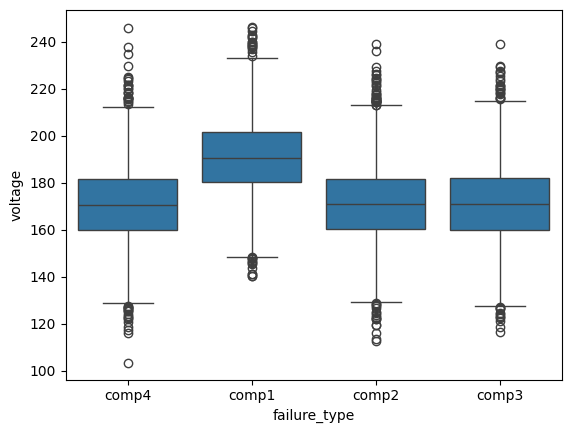

In [66]:
sns.boxplot(data=volt_24h_all,x='failure_type',y='voltage')


In [247]:
# To get rotation data fluctuation 24h before the failure occurance in all the machines

summary = []

for _, failure_row in failures.iterrows():

    failure_time = failure_row["datetime"]
    machine_id = failure_row["machineID"]
    failure_type = failure_row["failure"]

    rotate_24h = data_telemetry[
        (data_telemetry["machineID"] == machine_id) &
        (data_telemetry["datetime"] >= failure_time - pd.Timedelta(hours=24)) &
        (data_telemetry["datetime"] < failure_time)
    ]

    for _, telemetry_row in rotate_24h.iterrows():

        summary.append({
            "machineID": machine_id,
            "failure_time": failure_time,
            "failure_type": failure_type,
            "rotate_time": telemetry_row["datetime"],
            "rotation": telemetry_row["rotate"],
            "hrs_before_failure":
                (failure_time - telemetry_row["datetime"]).total_seconds()/3600
        })

rotate_24h_all = pd.DataFrame(summary)
#pd.pandas.set_option('display.max_rows',None)

In [248]:
rotate_24h_all

,machineID,failure_time,failure_type,rotate_time,rotation,hrs_before_failure
0,1,2015-01-05 06:00:00,comp4,2015-01-04 06:00:00,448.468838,24.0
1,1,2015-01-05 06:00:00,comp4,2015-01-04 07:00:00,433.279499,23.0
2,1,2015-01-05 06:00:00,comp4,2015-01-04 08:00:00,479.615136,22.0
3,1,2015-01-05 06:00:00,comp4,2015-01-04 09:00:00,438.091311,21.0
4,1,2015-01-05 06:00:00,comp4,2015-01-04 10:00:00,440.162685,20.0
...,...,...,...,...,...,...
18205,100,2015-12-09 06:00:00,comp2,2015-12-09 01:00:00,402.510934,5.0
18206,100,2015-12-09 06:00:00,comp2,2015-12-09 02:00:00,362.514598,4.0
18207,100,2015-12-09 06:00:00,comp2,2015-12-09 03:00:00,386.937494,3.0
18208,100,2015-12-09 06:00:00,comp2,2015-12-09 04:00:00,422.498178,2.0


In [249]:
rotate_24h_all.shape

(18210, 6)

In [250]:
rotate_24h_all.groupby("failure_type").agg({"rotation":["count","min","max","mean","std"]})

rotation                                               
                count         min         max        mean        std
failure_type                                                        
comp1            4581  220.909003  619.705260  442.707080  54.666662
comp2            6207  138.432075  544.333732  368.665217  51.378457
comp3            3135  138.432075  628.400405  443.202348  55.192834
comp4            4287  233.781108  638.318184  441.181987  56.475608

In [251]:
data_telemetry.agg({"rotate":["count","min","max","mean","std"]})

,rotate
count,876100.000000
min,138.432075
max,695.020984
mean,446.605119
std,52.673886


<Axes: xlabel='failure_type', ylabel='rotation'>

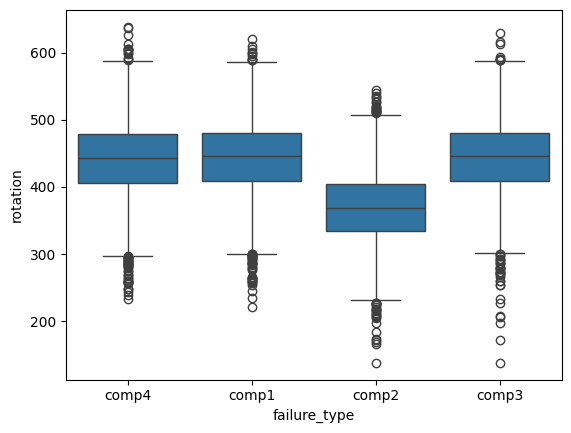

In [252]:
sns.boxplot(data=rotate_24h_all,x='failure_type',y='rotation')

### Analysis of rotation values in the 24-hour period preceding failures revealed that comp2 failures are associated with substantially lower rotation values. The mean rotation prior to comp2 failures was approximately 368.7 compared to the fleet-wide average of 446.6 and approximately 442 for comp1, comp3, and comp4 failures. The boxplot confirms that the entire rotation distribution for comp2 is shifted downward, suggesting that reduced rotation may be an important indicator of impending comp2 failures.

In [253]:
# To get pressure fluctuation 24h before the failure occurance in all the machines

summary = []

for _, failure_row in failures.iterrows():

    failure_time = failure_row["datetime"]
    machine_id = failure_row["machineID"]
    failure_type = failure_row["failure"]

    pressure_24h = data_telemetry[
        (data_telemetry["machineID"] == machine_id) &
        (data_telemetry["datetime"] >= failure_time - pd.Timedelta(hours=24)) &
        (data_telemetry["datetime"] < failure_time)
    ]

    for _, telemetry_row in pressure_24h.iterrows():

        summary.append({
            "machineID": machine_id,
            "failure_time": failure_time,
            "failure_type": failure_type,
            "rotate_time": telemetry_row["datetime"],
            "pressure": telemetry_row["pressure"],
            "hrs_before_failure":
                (failure_time - telemetry_row["datetime"]).total_seconds()/3600
        })

pressure_24h_all = pd.DataFrame(summary)
pressure_24h_all

,machineID,failure_time,failure_type,rotate_time,pressure,hrs_before_failure
0,1,2015-01-05 06:00:00,comp4,2015-01-04 06:00:00,97.709630,24.0
1,1,2015-01-05 06:00:00,comp4,2015-01-04 07:00:00,118.853452,23.0
2,1,2015-01-05 06:00:00,comp4,2015-01-04 08:00:00,101.999663,22.0
3,1,2015-01-05 06:00:00,comp4,2015-01-04 09:00:00,113.100915,21.0
4,1,2015-01-05 06:00:00,comp4,2015-01-04 10:00:00,94.524894,20.0
...,...,...,...,...,...,...
18205,100,2015-12-09 06:00:00,comp2,2015-12-09 01:00:00,89.586774,5.0
18206,100,2015-12-09 06:00:00,comp2,2015-12-09 02:00:00,88.304637,4.0
18207,100,2015-12-09 06:00:00,comp2,2015-12-09 03:00:00,110.906433,3.0
18208,100,2015-12-09 06:00:00,comp2,2015-12-09 04:00:00,90.986648,2.0


In [254]:
pressure_24h_all.shape

(18210, 6)

In [255]:
data_telemetry.agg({"pressure":["count","min","max","mean","std"]})

,pressure
count,876100.000000
min,51.237106
max,185.951998
mean,100.858668
std,11.048679


In [256]:
pressure_24h_all.groupby("failure_type").agg({"pressure":["count","min","max","mean","std"]})

pressure                                              
                count        min         max        mean        std
failure_type                                                       
comp1            4581  58.281550  171.176055  101.550693  12.081226
comp2            6207  59.331808  159.171623  101.546486  11.694433
comp3            3135  88.201340  171.176055  125.484437  10.510838
comp4            4287  54.170030  169.518052  101.130733  11.719177

<Axes: xlabel='failure_type', ylabel='pressure'>

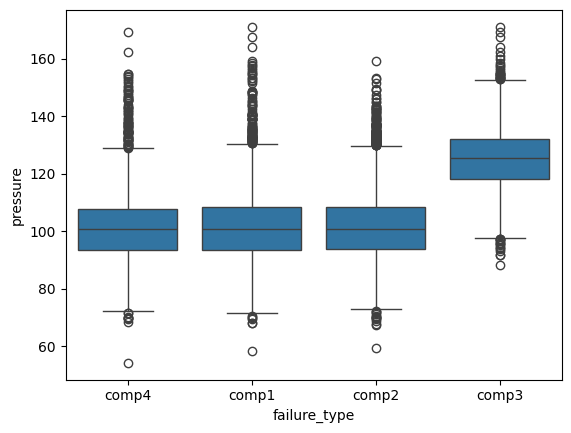

In [257]:
sns.boxplot(data=pressure_24h_all,x='failure_type',y='pressure')

### Analysis of pressure values in the 24-hour period preceding failures revealed that comp3 failures are associated with substantially higher pressure values. The mean pressure prior to comp3 failures was approximately 100.8 compared to the average of 125.4 and approximately 101 for comp1, comp2, and comp4 failures. The boxplot confirms that the entire pressure distribution for comp3 is shifted upward, suggesting that increased pressure may be an important indicator of impending comp3 failures.

In [258]:
# To get vibration fluctuation 24h before the failure occurance in all the machines

summary = []

for _, failure_row in failures.iterrows():

    failure_time = failure_row["datetime"]
    machine_id = failure_row["machineID"]
    failure_type = failure_row["failure"]

    vibration_24h = data_telemetry[
        (data_telemetry["machineID"] == machine_id) &
        (data_telemetry["datetime"] >= failure_time - pd.Timedelta(hours=24)) &
        (data_telemetry["datetime"] < failure_time)
    ]

    for _, telemetry_row in vibration_24h.iterrows():

        summary.append({
            "machineID": machine_id,
            "failure_time": failure_time,
            "failure_type": failure_type,
            "rotate_time": telemetry_row["datetime"],
            "vibration": telemetry_row["vibration"],
            "hrs_before_failure":
                (failure_time - telemetry_row["datetime"]).total_seconds()/3600
        })

vibration_24h_all = pd.DataFrame(summary)
vibration_24h_all

,machineID,failure_time,failure_type,rotate_time,vibration,hrs_before_failure
0,1,2015-01-05 06:00:00,comp4,2015-01-04 06:00:00,48.238941,24.0
1,1,2015-01-05 06:00:00,comp4,2015-01-04 07:00:00,54.848731,23.0
2,1,2015-01-05 06:00:00,comp4,2015-01-04 08:00:00,52.882567,22.0
3,1,2015-01-05 06:00:00,comp4,2015-01-04 09:00:00,53.695544,21.0
4,1,2015-01-05 06:00:00,comp4,2015-01-04 10:00:00,57.411078,20.0
...,...,...,...,...,...,...
18205,100,2015-12-09 06:00:00,comp2,2015-12-09 01:00:00,37.662014,5.0
18206,100,2015-12-09 06:00:00,comp2,2015-12-09 02:00:00,33.997760,4.0
18207,100,2015-12-09 06:00:00,comp2,2015-12-09 03:00:00,41.636435,3.0
18208,100,2015-12-09 06:00:00,comp2,2015-12-09 04:00:00,44.406312,2.0


In [259]:
vibration_24h_all.shape

(18210, 6)

In [260]:
data_telemetry.agg({"vibration":["count","min","max","mean","std"]})

,vibration
count,876100.000000
min,14.877054
max,76.791072
mean,40.385007
std,5.370361


In [261]:
vibration_24h_all.groupby("failure_type").agg({"vibration":["count","min","max","mean","std"]})

vibration                                           
                 count        min        max       mean       std
failure_type                                                     
comp1             4581  20.883873  73.948949  40.482089  5.567371
comp2             6207  21.883375  70.296929  40.793252  5.820690
comp3             3135  21.541257  61.369854  40.419093  5.342824
comp4             4287  34.772468  71.752014  50.391050  5.455272

<Axes: xlabel='failure_type', ylabel='vibration'>

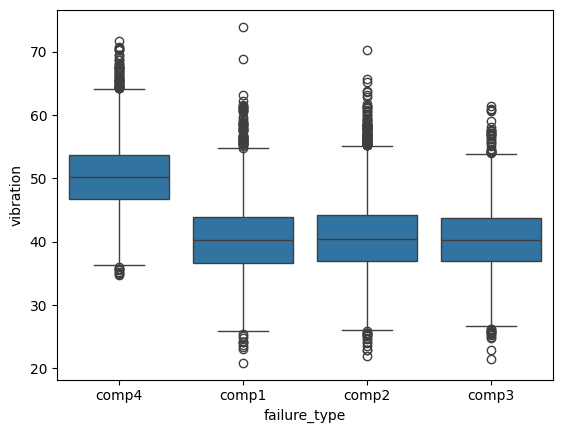

In [262]:
import seaborn as sns
sns.boxplot(data=vibration_24h_all,x='failure_type',y='vibration')

### Analysis of vibration values in the 24-hour period preceding failures revealed that comp4 failures are associated with substantially higher vibration values of 50.39 compared to the normal average of 40.38 and approximately 40.5 for comp1, comp2, and comp3 failures. The boxplot confirms that the entire vibration distribution for comp4 is shifted upward, suggesting that increased vibration may be an important indicator of impending comp4 failures.

In [158]:
# To get the data of all component maintianence done 14 days before the failure occurance in all the machines

summary = []

for _, failure_row in failures.iterrows():

    failure_time = failure_row["datetime"]
    machine_id = failure_row["machineID"]
    failure_type = failure_row["failure"]

    maint_24h = maintenance[
        (maintenance["machineID"] == machine_id) &
        (maintenance["datetime"] >= failure_time - pd.Timedelta(days=14))&
        (maintenance["datetime"] < failure_time)
    ]
    #latest_maint=maint_24h['datetime'].max()
    #print(type(maint_24h))
    if not maint_24h.empty:
        latest_maint_row = maint_24h.loc[maint_24h['datetime'].idxmax()]
        summary.append({
            "machineID": machine_id,
            "failure_time": failure_time,
            "maintanence_time":latest_maint_row["datetime"],
            "comp_type": latest_maint_row["comp"],
            #"rotate_time": telemetry_row["datetime"],
            #"vibration": telemetry_row["vibration"],
            "days_since_maintainence":
                (failure_time - latest_maint_row["datetime"]).total_seconds()/(3600*24)
        })

maint_2w_all = pd.DataFrame(summary)
maint_2w_all

,machineID,failure_time,maintanence_time,comp_type,days_since_maintainence
0,17,2015-01-02 03:00:00,2015-01-01 06:00:00,comp4,0.875
1,22,2015-01-02 03:00:00,2014-12-28 06:00:00,comp1,4.875
2,45,2015-01-02 03:00:00,2014-12-28 06:00:00,comp1,4.875
3,48,2015-01-11 06:00:00,2014-12-28 06:00:00,comp4,14.000
4,51,2015-01-02 03:00:00,2015-01-01 06:00:00,comp1,0.875
5,59,2015-01-02 03:00:00,2014-12-28 06:00:00,comp1,4.875
6,79,2015-01-02 03:00:00,2014-12-28 06:00:00,comp1,4.875
7,83,2015-01-02 03:00:00,2015-01-01 06:00:00,comp2,0.875
8,86,2015-01-02 03:00:00,2014-12-28 06:00:00,comp1,4.875
9,99,2015-01-02 03:00:00,2014-12-28 06:00:00,comp2,4.875


### Within a 14-day window following maintenance activities, 10 failure events were observed. Three failures occurred within 24 hours of a maintenance event:



### Machine 51 after maintenance of comp1,Machine 83 after maintenance of comp2,Machine 17 after maintenance of comp4



### Six additional failures occurred approximately 5 days after maintenance.Five involved comp1-maintained machines (Machines 22, 45, 59, 79, and 86)and One involved a comp2-maintained machine (Machine 99)




### One failure occurred 14 days after a comp4 maintenance event on Machine 48.No failures were observed within the analyzed 14-day window following comp3 maintenance activities.

In [263]:
# Check the Overall maintainence of components done versus the latest maintainence done within 14 days of failure
maintenance["comp"].value_counts()

comp
comp2    863
comp4    811
comp3    808
comp1    804
Name: count, dtype: int64

In [264]:
maint_2w_all["comp_type"].value_counts()

comp_type
comp1    6
comp4    2
comp2    2
Name: count, dtype: int64

### We see that 6 failures in 14 days of maintianence of comp1 comapred th the 804 maintianence activirwes performed.
comp1 : 6/804=0.7%
comp2 : 2/863= 0.2%
comp3 : 0%
comp4 : 2/811=0.24%

### Comp1 appears to be the most failure-prone component in the dataset. Failures of comp1 are associated with elevated voltage levels prior to failure and also exhibit the highest post-maintenance failure rate within a 14-day observation window.

In [265]:
machine['model'].value_counts()

model
model3    35
model4    32
model2    17
model1    16
Name: count, dtype: int64

In [266]:
# Merging the machine data containing the model,age with the failure data using machineID

failure_machines=failures.merge(machine,on='machineID',how='left')

In [267]:
failure_machines

,datetime,machineID,failure,model,age
0,2015-01-05 06:00:00,1,comp4,model3,18
1,2015-03-06 06:00:00,1,comp1,model3,18
2,2015-04-20 06:00:00,1,comp2,model3,18
3,2015-06-19 06:00:00,1,comp4,model3,18
4,2015-09-02 06:00:00,1,comp4,model3,18
...,...,...,...,...,...
756,2015-11-29 06:00:00,99,comp3,model1,14
757,2015-12-14 06:00:00,99,comp4,model1,14
758,2015-02-12 06:00:00,100,comp1,model4,5
759,2015-09-10 06:00:00,100,comp1,model4,5


<Axes: xlabel='failure', ylabel='age'>

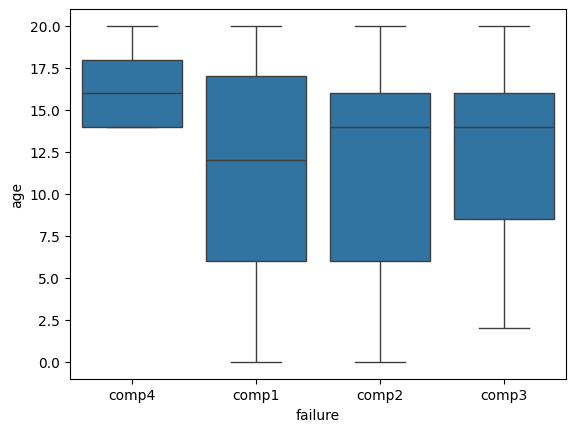

In [268]:
import seaborn as sns
sns.boxplot(failure_machines,x='failure',y='age')

In [165]:
failure_machines['model'].value_counts()

model
model3    221
model1    189
model4    183
model2    168
Name: count, dtype: int64

In [166]:
failure_machines['failure'].value_counts()

failure
comp2    259
comp1    192
comp4    179
comp3    131
Name: count, dtype: int64

In [167]:
failure_machines['age'].value_counts()

age
14    145
20     68
18     60
17     59
15     56
10     53
16     51
2      38
19     38
7      32
6      26
3      25
9      24
5      21
4      19
1      17
11     11
12      9
8       5
0       4
Name: count, dtype: int64

In [169]:
# To get the count of machine age & its mean age for each comp failure
failure_machines.groupby("failure").agg({"age":["count","max","mean","std"]})

age                         
        count max       mean       std
failure                               
comp1     192  20  11.291667  5.997236
comp2     259  20  11.123552  5.944852
comp3     131  20  12.183206  5.553656
comp4     179  20  16.480447  2.141985

In [273]:
df=pd.crosstab(failure_machines["model"],failure_machines["failure"])
df

failure,comp1,comp2,comp3,comp4
model,,,,
model1,33,46,68,42
model2,30,41,63,34
model3,68,89,0,64
model4,61,83,0,39


<Axes: xlabel='model', ylabel='age'>

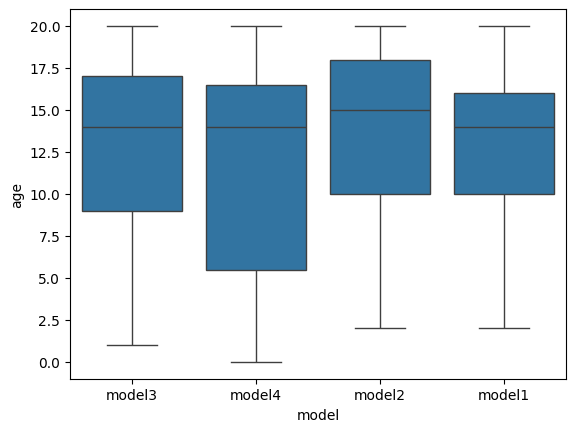

In [173]:
import seaborn as sns
sns.boxplot(failure_machines,x='model',y='age')

In [174]:
failure_machines.groupby("model").agg({"age":["count","max","mean","std"]})

age                         
       count max       mean       std
model                                
model1   189  20  12.693122  4.928316
model2   168  20  13.523810  5.889148
model3   221  20  13.004525  5.358509
model4   183  20  11.202186  6.294738

### Observation:


### Comp3 failures occur only in Model1 and Model2

### Models 3 and 4 show no Comp3 failures

### Comp2 is the most frequent failure overall

### Feature Engineering

In [289]:
# Below data is the actual telemetry combined with machine data's model and age
data_telemetry

,datetime,machineID,volt,rotate,pressure,vibration,model,age
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686,model3,18
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973,model3,18
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847,model3,18
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144,model3,18
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511,model3,18
...,...,...,...,...,...,...,...,...
876095,2016-01-01 02:00:00,100,179.438162,395.222827,102.290715,50.771941,model4,5
876096,2016-01-01 03:00:00,100,189.617555,446.207972,98.180607,35.123072,model4,5
876097,2016-01-01 04:00:00,100,192.483414,447.816524,94.132837,48.314561,model4,5
876098,2016-01-01 05:00:00,100,165.475310,413.771670,104.081073,44.835259,model4,5


In [290]:
failures

,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4
...,...,...,...
756,2015-11-29 06:00:00,99,comp3
757,2015-12-14 06:00:00,99,comp4
758,2015-02-12 06:00:00,100,comp1
759,2015-09-10 06:00:00,100,comp1


In [291]:
failure_machines=failure_machines.rename(columns={'failure':'failure_type'})

In [292]:
failure_machines

,datetime,machineID,failure_type,model,age
0,2015-01-05 06:00:00,1,comp4,model3,18
1,2015-03-06 06:00:00,1,comp1,model3,18
2,2015-04-20 06:00:00,1,comp2,model3,18
3,2015-06-19 06:00:00,1,comp4,model3,18
4,2015-09-02 06:00:00,1,comp4,model3,18
...,...,...,...,...,...
756,2015-11-29 06:00:00,99,comp3,model1,14
757,2015-12-14 06:00:00,99,comp4,model1,14
758,2015-02-12 06:00:00,100,comp1,model4,5
759,2015-09-10 06:00:00,100,comp1,model4,5


In [293]:
# Create a new copy failure_df so as to add the engineered features done as EDA
failure_df=failure_machines.copy()

In [294]:
failure_df["error_count_24h"] = 0
failure_df["error1_count_24h"] = 0
failure_df["error2_count_24h"] = 0
failure_df["error3_count_24h"] = 0
failure_df["error4_count_24h"] = 0
failure_df["error5_count_24h"] = 0

In [295]:
# Adding the engineered features of each error count to the failure_df dataset

for idx, row in failure_df.iterrows():
    failure_time = row["datetime"]
    machine_id = row["machineID"]

    errors_24h = errors[
        (errors["machineID"] == machine_id) &
        (errors["datetime"] >= failure_time - pd.Timedelta(hours=24)) &
        (errors["datetime"] < failure_time)
    ]

    failure_df.loc[idx, "error_count_24h"] = len(errors_24h)


    failure_df.loc[idx, "error1_count_24h"] = (errors_24h["errorID"]=="error1").sum()
    failure_df.loc[idx, "error2_count_24h"] = (errors_24h["errorID"]=="error2").sum()
    failure_df.loc[idx, "error3_count_24h"] = (errors_24h["errorID"]=="error3").sum()
    failure_df.loc[idx, "error4_count_24h"] = (errors_24h["errorID"]=="error4").sum()
    failure_df.loc[idx, "error5_count_24h"] = (errors_24h["errorID"]=="error5").sum()
    

    
    

In [296]:
failure_df

,datetime,machineID,failure_type,model,age,error_count_24h,error1_count_24h,error2_count_24h,error3_count_24h,error4_count_24h,error5_count_24h
0,2015-01-05 06:00:00,1,comp4,model3,18,1,0,0,0,0,1
1,2015-03-06 06:00:00,1,comp1,model3,18,1,1,0,0,0,0
2,2015-04-20 06:00:00,1,comp2,model3,18,2,0,1,1,0,0
3,2015-06-19 06:00:00,1,comp4,model3,18,1,0,0,0,0,1
4,2015-09-02 06:00:00,1,comp4,model3,18,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
756,2015-11-29 06:00:00,99,comp3,model1,14,1,0,0,0,1,0
757,2015-12-14 06:00:00,99,comp4,model1,14,1,0,0,0,0,1
758,2015-02-12 06:00:00,100,comp1,model4,5,1,1,0,0,0,0
759,2015-09-10 06:00:00,100,comp1,model4,5,1,1,0,0,0,0


In [297]:
failure_df["days_since_maintainence"]=0

In [298]:
# Adding the feature "days_since_maintainence" to the failure_df dataset
for idx, row in failure_df.iterrows():
    failure_time = row["datetime"]
    machine_id = row["machineID"]

    maint_24h = maintenance[
        (maintenance["machineID"] == machine_id) &
        (maintenance["datetime"] >= failure_time - pd.Timedelta(days=14))&
        (maintenance["datetime"] < failure_time)]

    if not maint_24h.empty:
        latest_maint_row = maint_24h.loc[maint_24h['datetime'].idxmax()]

        failure_df.loc[idx,"days_since_maintainence"]=(failure_time - latest_maint_row["datetime"]).total_seconds()/(3600*24)

        
    

C:\Users\tsaivign\AppData\Local\Temp\ipykernel_3392\2016935607.py:14: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.875' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  failure_df.loc[idx,"days_since_maintainence"]=(failure_time - latest_maint_row["datetime"]).total_seconds()/(3600*24)


In [299]:
failure_df

,datetime,machineID,failure_type,model,age,error_count_24h,error1_count_24h,error2_count_24h,error3_count_24h,error4_count_24h,error5_count_24h,days_since_maintainence
0,2015-01-05 06:00:00,1,comp4,model3,18,1,0,0,0,0,1,0.0
1,2015-03-06 06:00:00,1,comp1,model3,18,1,1,0,0,0,0,0.0
2,2015-04-20 06:00:00,1,comp2,model3,18,2,0,1,1,0,0,0.0
3,2015-06-19 06:00:00,1,comp4,model3,18,1,0,0,0,0,1,0.0
4,2015-09-02 06:00:00,1,comp4,model3,18,1,0,0,0,0,1,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
756,2015-11-29 06:00:00,99,comp3,model1,14,1,0,0,0,1,0,0.0
757,2015-12-14 06:00:00,99,comp4,model1,14,1,0,0,0,0,1,0.0
758,2015-02-12 06:00:00,100,comp1,model4,5,1,1,0,0,0,0,0.0
759,2015-09-10 06:00:00,100,comp1,model4,5,1,1,0,0,0,0,0.0


In [300]:
failure_df["mean_voltage_24h"] = 0
failure_df["mean_rotation_24h"] = 0
failure_df["mean_pressure_24h"] = 0
failure_df["mean_vibration_24h"] = 0

In [301]:
failure_df

,datetime,machineID,failure_type,model,age,error_count_24h,error1_count_24h,error2_count_24h,error3_count_24h,error4_count_24h,error5_count_24h,days_since_maintainence,mean_voltage_24h,mean_rotation_24h,mean_pressure_24h,mean_vibration_24h
0,2015-01-05 06:00:00,1,comp4,model3,18,1,0,0,0,0,1,0.0,0,0,0,0
1,2015-03-06 06:00:00,1,comp1,model3,18,1,1,0,0,0,0,0.0,0,0,0,0
2,2015-04-20 06:00:00,1,comp2,model3,18,2,0,1,1,0,0,0.0,0,0,0,0
3,2015-06-19 06:00:00,1,comp4,model3,18,1,0,0,0,0,1,0.0,0,0,0,0
4,2015-09-02 06:00:00,1,comp4,model3,18,1,0,0,0,0,1,0.0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,2015-11-29 06:00:00,99,comp3,model1,14,1,0,0,0,1,0,0.0,0,0,0,0
757,2015-12-14 06:00:00,99,comp4,model1,14,1,0,0,0,0,1,0.0,0,0,0,0
758,2015-02-12 06:00:00,100,comp1,model4,5,1,1,0,0,0,0,0.0,0,0,0,0
759,2015-09-10 06:00:00,100,comp1,model4,5,1,1,0,0,0,0,0.0,0,0,0,0


In [302]:
# Adding all the engineered telemetry features to the failure_df dataset
for idx, row in failure_df.iterrows():
    failure_time = row["datetime"]
    machine_id = row["machineID"]

    all_telemetry_24h = data_telemetry[
        (data_telemetry["machineID"] == machine_id) &
        (data_telemetry["datetime"] >= failure_time - pd.Timedelta(hours=24)) &
        (data_telemetry["datetime"] < failure_time)
    ]
    failure_df.loc[idx, "mean_voltage_24h"]= all_telemetry_24h["volt"].mean()
    failure_df.loc[idx, "mean_rotation_24h"]= all_telemetry_24h["rotate"].mean()
    failure_df.loc[idx, "mean_pressure_24h"]= all_telemetry_24h["pressure"].mean()
    failure_df.loc[idx, "mean_vibration_24h"]= all_telemetry_24h["vibration"].mean()
    

C:\Users\tsaivign\AppData\Local\Temp\ipykernel_3392\1617041171.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '171.33356175944922' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  failure_df.loc[idx, "mean_voltage_24h"]= all_telemetry_24h["volt"].mean()
C:\Users\tsaivign\AppData\Local\Temp\ipykernel_3392\1617041171.py:12: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '441.3108943252858' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  failure_df.loc[idx, "mean_rotation_24h"]= all_telemetry_24h["rotate"].mean()
C:\Users\tsaivign\AppData\Local\Temp\ipykernel_3392\1617041171.py:13: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '98.08711494093554' has dtype incomp

In [303]:
failure_df

,datetime,machineID,failure_type,model,age,error_count_24h,error1_count_24h,error2_count_24h,error3_count_24h,error4_count_24h,error5_count_24h,days_since_maintainence,mean_voltage_24h,mean_rotation_24h,mean_pressure_24h,mean_vibration_24h
0,2015-01-05 06:00:00,1,comp4,model3,18,1,0,0,0,0,1,0.0,171.333562,441.310894,98.087115,51.607772
1,2015-03-06 06:00:00,1,comp1,model3,18,1,1,0,0,0,0,0.0,185.565503,441.035876,98.781707,39.950596
2,2015-04-20 06:00:00,1,comp2,model3,18,2,0,1,1,0,0,0.0,170.303958,374.896680,102.075598,40.007427
3,2015-06-19 06:00:00,1,comp4,model3,18,1,0,0,0,0,1,0.0,170.255196,459.815148,101.375959,47.838747
4,2015-09-02 06:00:00,1,comp4,model3,18,1,0,0,0,0,1,0.0,167.105571,443.125092,96.558697,57.578478
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,2015-11-29 06:00:00,99,comp3,model1,14,1,0,0,0,1,0,0.0,172.685109,453.830400,124.499786,39.536048
757,2015-12-14 06:00:00,99,comp4,model1,14,1,0,0,0,0,1,0.0,173.743478,386.721231,123.550547,50.045968
758,2015-02-12 06:00:00,100,comp1,model4,5,1,1,0,0,0,0,0.0,186.316136,445.662728,100.124055,39.095448
759,2015-09-10 06:00:00,100,comp1,model4,5,1,1,0,0,0,0,0.0,195.163659,453.258052,99.176512,40.733093


In [304]:
failure_df.isnull().sum()

datetime                   0
machineID                  0
failure_type               0
model                      0
age                        0
error_count_24h            0
error1_count_24h           0
error2_count_24h           0
error3_count_24h           0
error4_count_24h           0
error5_count_24h           0
days_since_maintainence    0
mean_voltage_24h           0
mean_rotation_24h          0
mean_pressure_24h          0
mean_vibration_24h         0
dtype: int64

In [305]:
failure_df["failure_type"].value_counts()

failure_type
comp2    259
comp1    192
comp4    179
comp3    131
Name: count, dtype: int64

### Looks more like a balanced dataset on the target

In [306]:
failure_df.describe()

,datetime,machineID,age,error_count_24h,error1_count_24h,error2_count_24h,error3_count_24h,error4_count_24h,error5_count_24h,days_since_maintainence,mean_voltage_24h,mean_rotation_24h,mean_pressure_24h,mean_vibration_24h
count,761,761.000000,761.000000,761.000000,761.000000,761.000000,761.000000,761.000000,761.000000,761.000000,761.000000,761.000000,761.000000,761.000000
mean,2015-06-24 12:12:17.976346880,51.911958,12.608410,1.546649,0.283837,0.391590,0.392904,0.211564,0.266754,0.060283,176.169177,417.220462,105.576237,42.909320
min,2015-01-02 03:00:00,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,160.318947,288.929157,92.666905,37.201346
25%,2015-03-23 06:00:00,24.000000,9.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,168.743091,374.010506,98.994897,39.531361
50%,2015-06-24 06:00:00,51.000000,14.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,171.584917,439.806981,100.692748,40.463827
75%,2015-09-23 06:00:00,79.000000,17.000000,2.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,186.702797,451.544658,103.760672,48.680436
max,2015-12-31 06:00:00,100.000000,20.000000,4.000000,2.000000,2.000000,2.000000,2.000000,2.000000,14.000000,214.375019,481.674252,150.481279,61.203474
std,NaN,29.515542,5.669088,0.709516,0.465509,0.496443,0.496728,0.415075,0.445517,0.667009,10.309714,41.448627,10.945261,4.883037


In [307]:
failure_df.columns

Index(['datetime', 'machineID', 'failure_type', 'model', 'age',
       'error_count_24h', 'error1_count_24h', 'error2_count_24h',
       'error3_count_24h', 'error4_count_24h', 'error5_count_24h',
       'days_since_maintainence', 'mean_voltage_24h', 'mean_rotation_24h',
       'mean_pressure_24h', 'mean_vibration_24h'],
      dtype='object')

In [308]:
failure_df.select_dtypes(include="object").columns

Index(['failure_type', 'model'], dtype='object')

### model, failure_type, machineID are categorical

In [309]:
failure_df["age"].value_counts()


age
14    145
20     68
18     60
17     59
15     56
10     53
16     51
2      38
19     38
7      32
6      26
3      25
9      24
5      21
4      19
1      17
11     11
12      9
8       5
0       4
Name: count, dtype: int64

In [310]:
# Moving the target column failure_type to the last
failure_df['failure_type'] = failure_df.pop('failure_type')

### Columns like Machine ID and Datetime are dropped as they dont directly become the cause for comp failures

In [311]:
failure_df.drop(columns=['machineID','datetime'],axis=1,inplace=True)

In [312]:
failure_df

,model,age,error_count_24h,error1_count_24h,error2_count_24h,error3_count_24h,error4_count_24h,error5_count_24h,days_since_maintainence,mean_voltage_24h,mean_rotation_24h,mean_pressure_24h,mean_vibration_24h,failure_type
0,model3,18,1,0,0,0,0,1,0.0,171.333562,441.310894,98.087115,51.607772,comp4
1,model3,18,1,1,0,0,0,0,0.0,185.565503,441.035876,98.781707,39.950596,comp1
2,model3,18,2,0,1,1,0,0,0.0,170.303958,374.896680,102.075598,40.007427,comp2
3,model3,18,1,0,0,0,0,1,0.0,170.255196,459.815148,101.375959,47.838747,comp4
4,model3,18,1,0,0,0,0,1,0.0,167.105571,443.125092,96.558697,57.578478,comp4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,model1,14,1,0,0,0,1,0,0.0,172.685109,453.830400,124.499786,39.536048,comp3
757,model1,14,1,0,0,0,0,1,0.0,173.743478,386.721231,123.550547,50.045968,comp4
758,model4,5,1,1,0,0,0,0,0.0,186.316136,445.662728,100.124055,39.095448,comp1
759,model4,5,1,1,0,0,0,0,0.0,195.163659,453.258052,99.176512,40.733093,comp1


#### Feature encoding the Target failure type to numeric and model name using dummies

In [313]:
failure_df['failure_type']=failure_df['failure_type'].map({'comp1':1,'comp2':2,'comp3':3,'comp4':4})

In [314]:
failure_df.head()

,model,age,error_count_24h,error1_count_24h,error2_count_24h,error3_count_24h,error4_count_24h,error5_count_24h,days_since_maintainence,mean_voltage_24h,mean_rotation_24h,mean_pressure_24h,mean_vibration_24h,failure_type
0,model3,18,1,0,0,0,0,1,0.0,171.333562,441.310894,98.087115,51.607772,4
1,model3,18,1,1,0,0,0,0,0.0,185.565503,441.035876,98.781707,39.950596,1
2,model3,18,2,0,1,1,0,0,0.0,170.303958,374.896680,102.075598,40.007427,2
3,model3,18,1,0,0,0,0,1,0.0,170.255196,459.815148,101.375959,47.838747,4
4,model3,18,1,0,0,0,0,1,0.0,167.105571,443.125092,96.558697,57.578478,4


In [315]:
failure_df=pd.get_dummies(failure_df,columns=['model'],dtype=int)

In [316]:
failure_df['failure_type'] = failure_df.pop('failure_type')

In [317]:
failure_df

,age,error_count_24h,error1_count_24h,error2_count_24h,error3_count_24h,error4_count_24h,error5_count_24h,days_since_maintainence,mean_voltage_24h,mean_rotation_24h,mean_pressure_24h,mean_vibration_24h,model_model1,model_model2,model_model3,model_model4,failure_type
0,18,1,0,0,0,0,1,0.0,171.333562,441.310894,98.087115,51.607772,0,0,1,0,4
1,18,1,1,0,0,0,0,0.0,185.565503,441.035876,98.781707,39.950596,0,0,1,0,1
2,18,2,0,1,1,0,0,0.0,170.303958,374.896680,102.075598,40.007427,0,0,1,0,2
3,18,1,0,0,0,0,1,0.0,170.255196,459.815148,101.375959,47.838747,0,0,1,0,4
4,18,1,0,0,0,0,1,0.0,167.105571,443.125092,96.558697,57.578478,0,0,1,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,14,1,0,0,0,1,0,0.0,172.685109,453.830400,124.499786,39.536048,1,0,0,0,3
757,14,1,0,0,0,0,1,0.0,173.743478,386.721231,123.550547,50.045968,1,0,0,0,4
758,5,1,1,0,0,0,0,0.0,186.316136,445.662728,100.124055,39.095448,0,0,0,1,1
759,5,1,1,0,0,0,0,0.0,195.163659,453.258052,99.176512,40.733093,0,0,0,1,1


In [318]:
failure_df.isnull().sum()

age                        0
error_count_24h            0
error1_count_24h           0
error2_count_24h           0
error3_count_24h           0
error4_count_24h           0
error5_count_24h           0
days_since_maintainence    0
mean_voltage_24h           0
mean_rotation_24h          0
mean_pressure_24h          0
mean_vibration_24h         0
model_model1               0
model_model2               0
model_model3               0
model_model4               0
failure_type               0
dtype: int64

### Time to train the model

In [206]:
# Including all the columns except the target as Input 
X=failure_df.drop(columns=['failure_type'],axis=1)

In [319]:
#Target failure as output
y=failure_df['failure_type']

In [320]:
X.shape

(761, 16)

In [321]:
y.value_counts()

failure_type
2    259
1    192
4    179
3    131
Name: count, dtype: int64

In [322]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [323]:
from sklearn.tree import DecisionTreeClassifier
treeclassifier=DecisionTreeClassifier()
treeclassifier.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


[Text(0.4697802197802198, 0.9615384615384616, 'x[3] <= 0.5\ngini = 0.736\nsamples = 608\nvalue = [150, 207, 105, 146]'),
 Text(0.21978021978021978, 0.8846153846153846, 'x[8] <= 180.208\ngini = 0.661\nsamples = 372\nvalue = [144, 2, 96, 130]'),
 Text(0.3447802197802198, 0.9230769230769231, 'True  '),
 Text(0.10989010989010989, 0.8076923076923077, 'x[11] <= 47.124\ngini = 0.498\nsamples = 216\nvalue = [0, 2, 91, 123]'),
 Text(0.06593406593406594, 0.7307692307692307, 'x[9] <= 368.684\ngini = 0.044\nsamples = 89\nvalue = [0, 2, 87, 0]'),
 Text(0.04395604395604396, 0.6538461538461539, 'x[8] <= 168.516\ngini = 0.444\nsamples = 3\nvalue = [0, 2, 1, 0]'),
 Text(0.02197802197802198, 0.5769230769230769, 'gini = 0.0\nsamples = 2\nvalue = [0, 2, 0, 0]'),
 Text(0.06593406593406594, 0.5769230769230769, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1, 0]'),
 Text(0.08791208791208792, 0.6538461538461539, 'gini = 0.0\nsamples = 86\nvalue = [0, 0, 86, 0]'),
 Text(0.15384615384615385, 0.7307692307692307, 'x[1

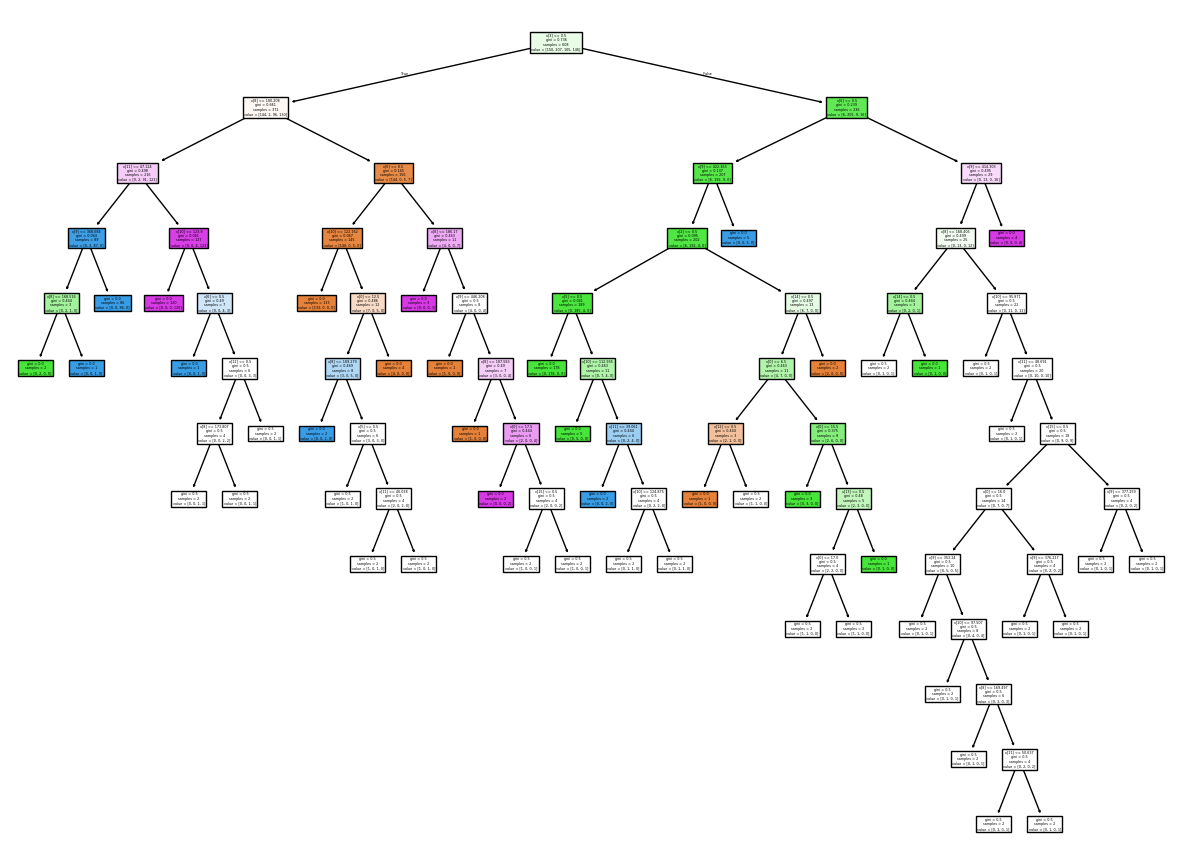

In [324]:
from sklearn import tree
plt.figure(figsize=(15,11))
tree.plot_tree(treeclassifier,filled=True)

In [325]:
y_pred=treeclassifier.predict(X_test)
from sklearn.metrics import confusion_matrix,classification_report
cm=confusion_matrix(y_test,y_pred)
print(cm)
print(classification_report(y_test,y_pred))

[[36  3  1  2]
 [ 5 44  3  0]
 [ 2  0 23  1]
 [ 2  2  0 29]]
              precision    recall  f1-score   support

           1       0.80      0.86      0.83        42
           2       0.90      0.85      0.87        52
           3       0.85      0.88      0.87        26
           4       0.91      0.88      0.89        33

    accuracy                           0.86       153
   macro avg       0.86      0.87      0.86       153
weighted avg       0.87      0.86      0.86       153



In [326]:
treeclassifier.feature_importances_

array([0.00972609, 0.        , 0.01173336, 0.34318348, 0.        ,
       0.00648736, 0.05195009, 0.        , 0.28395483, 0.03341814,
       0.02501752, 0.228758  , 0.00078928, 0.00094714, 0.00403471,
       0.        ])

In [327]:
treeclassifier.get_depth()

12

In [328]:
treeclassifier.get_n_leaves()

np.int64(47)

In [329]:
feature_importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": treeclassifier.feature_importances_
})

feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).head(20)

,Feature,Importance
3,error2_count_24h,0.343183
8,mean_voltage_24h,0.283955
11,mean_vibration_24h,0.228758
6,error5_count_24h,0.051950
9,mean_rotation_24h,0.033418
10,mean_pressure_24h,0.025018
2,error1_count_24h,0.011733
0,age,0.009726
5,error4_count_24h,0.006487
14,model_model3,0.004035


In [330]:
from sklearn.ensemble import RandomForestClassifier

In [331]:
rf=RandomForestClassifier(
    random_state=42
)

In [332]:
rf.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [333]:
y_pred=rf.predict(X_test)
#from sklearn.metrics import confusion_matrix,classification_report
cm=confusion_matrix(y_test,y_pred)
print(cm)
print(classification_report(y_test,y_pred))

[[37  3  0  2]
 [ 3 46  2  1]
 [ 2  0 23  1]
 [ 2  1  0 30]]
              precision    recall  f1-score   support

           1       0.84      0.88      0.86        42
           2       0.92      0.88      0.90        52
           3       0.92      0.88      0.90        26
           4       0.88      0.91      0.90        33

    accuracy                           0.89       153
   macro avg       0.89      0.89      0.89       153
weighted avg       0.89      0.89      0.89       153



In [334]:
rf.feature_importances_

array([0.01416041, 0.03918137, 0.08684473, 0.09917101, 0.07469882,
       0.05804313, 0.11020264, 0.00103913, 0.12513191, 0.16114059,
       0.09165546, 0.12068019, 0.00366909, 0.00438679, 0.00600746,
       0.00398727])

In [335]:
feature_importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).head(20)

,Feature,Importance
9,mean_rotation_24h,0.161141
8,mean_voltage_24h,0.125132
11,mean_vibration_24h,0.120680
6,error5_count_24h,0.110203
3,error2_count_24h,0.099171
10,mean_pressure_24h,0.091655
2,error1_count_24h,0.086845
4,error3_count_24h,0.074699
5,error4_count_24h,0.058043
1,error_count_24h,0.039181




Built a predictive maintenance multiclass classification system using:



Telemetry data

Error logs

Maintenance history

Machine metadata

EDA Findings

Identified distinct failure signatures:



Comp1 → Elevated voltage

Comp2 → Reduced rotation

Comp3 → Elevated pressure

Comp4 → Elevated vibration


Feature Engineering



Created:

Error frequency features

Telemetry aggregation features

Maintenance-history features

Machine age/model features



Modeling Results

Model	Accuracy


Decision Tree	88%

    
Random Forest	89%

###Key Predictors

Random Forest identified:

Rotation

Voltage

Vibration

Error5 frequency

Error2 frequency

Pressure

as the strongest predictors of component failure.